# M6.2 · 实时风控与熔断

> 实时风控分事前/事中/事后三层，用限额约束交易，用熔断器在风险越限时自动停止开新仓，
> 极端情况下用 kill switch 一键停机。

## 一、机制

1. **多层限额**：单票权重、总杠杆、行业敞口、现金比例，下单前综合校验；
2. **熔断器状态机**：NORMAL → 指标越限 TRIPPED（停止开新仓）→ 人工/冷却 RESET；
3. **Kill switch**：紧急停机，立即撤所有单并锁定，需人工解锁。

## 二、限额与熔断

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import realtime_risk as rr
limits = rr.RiskLimits(max_weight=0.05, max_gross=1.0, max_industry=0.3, min_cash=0.05)
ok, viol = limits.check_order(new_weight=0.08, gross=0.9, industry_exp=0.2, cash_ratio=0.1)
print('超限单放行=%s 违规=%s' % (ok, viol))
print('合规单放行=%s' % limits.check_order(0.04, 0.9, 0.2, 0.1)[0])
cb = rr.CircuitBreaker(threshold=0.1)
trace = [cb.evaluate(x) for x in [0.04, 0.06, 0.12, 0.03, 0.02]]
print('熔断状态轨迹:', trace)
print('复位:', cb.reset())
ks = rr.KillSwitch()
print('kill switch:', ks.trigger('系统异常'), '解锁:', ks.disarm())

超限单放行=False 违规=['WEIGHT']
合规单放行=True
熔断状态轨迹: ['NORMAL', 'NORMAL', 'TRIPPED', 'TRIPPED', 'TRIPPED']
复位: NORMAL
kill switch: {'kill': True, 'cancel_all': True, 'reason': '系统异常'} 解锁: DISARMED


## 三、可视化

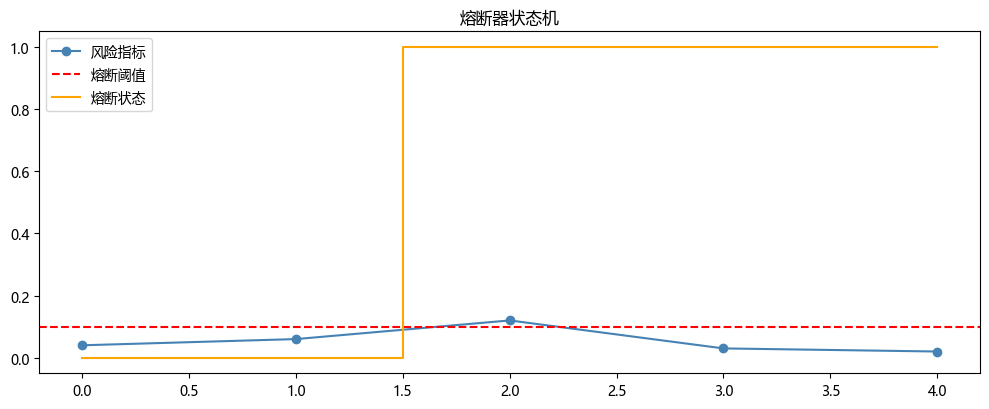

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 4.2))
metrics = [0.04, 0.06, 0.12, 0.03, 0.02]
states = [1 if s == 'TRIPPED' else 0 for s in trace]
ax.plot(metrics, 'o-', color='steelblue', label='风险指标')
ax.axhline(0.1, color='red', ls='--', label='熔断阈值')
ax.step(range(5), states, where='mid', color='orange', label='熔断状态')
ax.set_title('熔断器状态机'); ax.legend()
plt.tight_layout(); plt.show()

## 四、面试要点

- **事前/事中/事后风控分别做什么？** 事前校验限额与可成交性；事中监控敞口/回撤触发熔断；事后对账留档。
- **熔断与 kill switch 的区别？** 熔断是自动暂停开新仓、可冷却复位；kill switch 是人工/系统紧急停机并全部撤单，需人工解锁。
- **熔断后为何不能自动恢复？** 需确认风险解除、避免在异常行情中反复触发，通常人工评估后复位。
- **限额如何避免被绕过？** 风控在订单进入柜台前强制拦截，且与策略解耦，策略无法跳过。

## 五、练习

1. 增加行业/风格级限额。
2. 实现分级熔断（警告/减仓/停机）。
3. 记录每次熔断的触发指标与时间。
4. 讨论多账户下的统一限额管理。